In [1]:
from greenbowl_boot import load_my_experiment, ALPHA, BREAKEVEN, DESIGN_MDE
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind
from joblib import Parallel, delayed
from statsmodels.stats.proportion import proportion_confint
from dataclasses import dataclass, field
import matplotlib_inline
import warnings
from matplotlib.lines import Line2D
from scipy.stats import norm

warnings.filterwarnings("ignore")
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')

## Data

In [2]:
STUDENT_ID = "ozhelezniakov@kse.org.ua"   # <-- put YOUR id here
exp = load_my_experiment(STUDENT_ID)

print(exp)                     # city, arm sizes, user base
print(exp.data.head())         # one row per user: user_id, arm, revenue
control, test = exp.control, exp.test
print(f"annual revenue at stake: {exp.annual_revenue/1e6:.0f} M UAH")

<Experiment city=np.str_('Sumy') n_control=5121 n_test=4992 user_base=98600 metric=2-week ARPU (UAH)>
      user_id      arm  revenue
0  u_36460309  control   557.47
1  u_73317642  control   475.77
2  u_28119658  control     0.00
3  u_68187223  control   733.10
4  u_34357369  control  1199.93
annual revenue at stake: 1065 M UAH


## Welch t-test

In [3]:
# --- the platform's automated headline (as-is, warts and all) -------------
t_stat, p = ttest_ind(test, control, equal_var=False)
d_hat = test.mean() - control.mean()
se = np.sqrt(test.var(ddof=1)/test.size + control.var(ddof=1)/control.size)
naive = (d_hat - 1.96*se) / control.mean(), (d_hat + 1.96*se) / control.mean()

print(f"ARPU uplift: {d_hat/control.mean():+.2%}   "
      f"'95% CI': ({naive[0]:+.2%}, {naive[1]:+.2%})   p-value = {p:.3g}")
print("HEADLINE:",
      "SHIP — significant uplift" if p < ALPHA and d_hat > 0 else
      "ROLL BACK — significant drop" if p < ALPHA else
      "DON'T SHIP — no significant uplift")

ARPU uplift: +12.33%   '95% CI': (+2.40%, +22.25%)   p-value = 0.0149
HEADLINE: SHIP — significant uplift


## Describe
---
* Двохмодальний розподіл тестової групи через `arpu = 0`

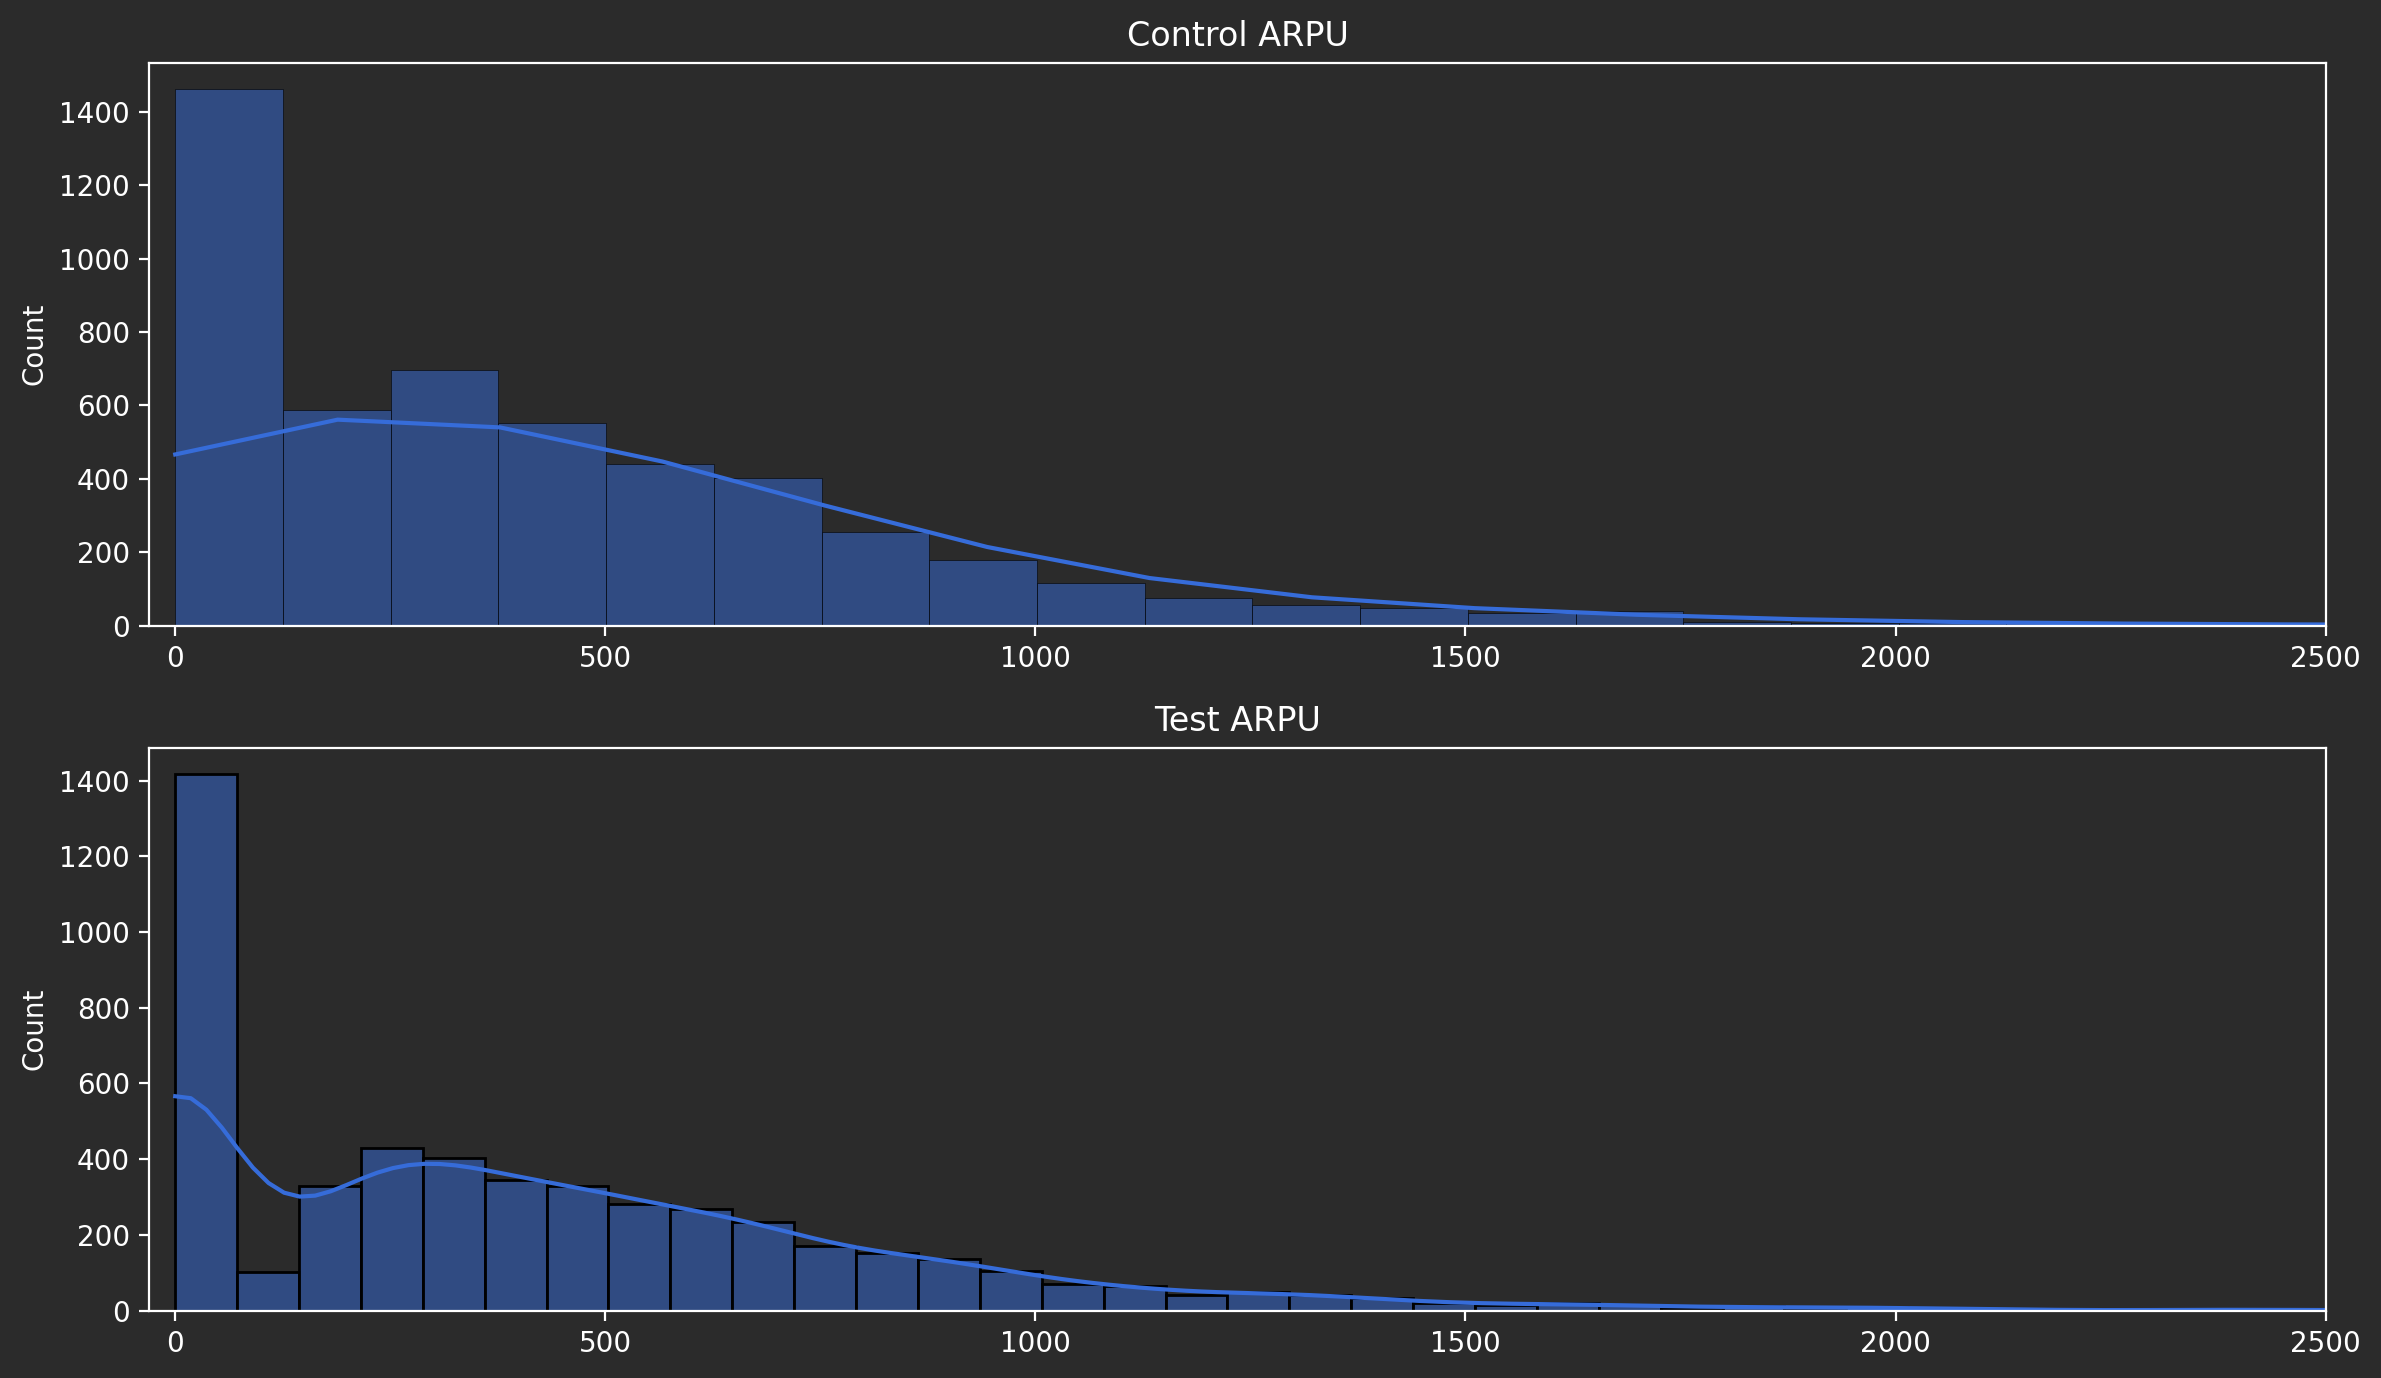

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7))

sns.histplot(test, kde=True, ax=ax[0], bins=300)
sns.histplot(control, kde=True, ax=ax[1])

ax[0].set_title("Control ARPU")
ax[1].set_title("Test ARPU")
ax[0].set_xlim(-30, 2500)
ax[1].set_xlim(-30, 2500)

plt.tight_layout()
plt.show()

In [5]:
median_test = np.median(test)
median_control = np.median(control)

mean_test = np.mean(test)
mean_control = np.mean(control)

count_zero_test = len(test) - np.count_nonzero(test)
count_zero_conrol = len(control) - np.count_nonzero(control)

print(f"Median test: {median_test:.2f}  Median control: {median_control:.0f}")
print(f"Mean test: {mean_test:.2f} \t Mean control: {mean_control:.2f}")
print(f"Zeroes test: {count_zero_test:.0f} \t Zeroes control: {count_zero_conrol:.0f}")

Median test: 334.26  Median control: 336
Mean test: 466.48 	 Mean control: 415.29
Zeroes test: 1409 	 Zeroes control: 1415


In [6]:
top5_hold_test = np.sum(np.sort(test)[-5:])
top5_hold_control = np.sum(np.sort(control)[-5:])

top1_hold_test = np.sum(np.sort(test)[-1])
top1_hold_control = np.sum(np.sort(control)[-1])

print(f"!!Top-5 users hold test: {(top5_hold_test / np.sum(test)):<13.2%} Top-5 users control: {(top5_hold_control / np.sum(control)):.2%}")
print(f"Top-1 users test: {(top1_hold_test / np.sum(test)):<19.2%}  Top-1 users hold control: {(top1_hold_control/ np.sum(control)):.2%} ")


!!Top-5 users hold test: 7.86%         Top-5 users control: 0.71%
Top-1 users test: 1.61%                Top-1 users hold control: 0.17% 


In [7]:
@dataclass(slots=True)
class MyBootstrap_2samp_perc:
    test: np.ndarray
    control: np.ndarray
    stat: function = np.mean
    alpha: float = 0.05
    B: int = 10_000
    seed: int = 42
    boot_metric_sample: np.ndarray = field(init=False, default=None)
    rng: np.random.Generator = field(init=False)
    theta_hat:float = field(init=False)
    weights_test: np.ndarray = field(init=False, default=None)
    weights_control: np.ndarray = field(init=False, default=None)
    ci_low: float = field(init=False, default=None)
    ci_high: float = field(init=False, default=None)

    def __post_init__(self):
        self.rng: np.random.Generator = np.random.default_rng(self.seed)
        self.theta_hat:float = self.stat(self.test) / self.stat(self.control) - 1

    @staticmethod
    def _single_bootsrap(test, control, seed, fun):
        rng = np.random.default_rng(seed)

        boot_sample_test = rng.choice(test, size=len(test), replace=True)
        boot_sample_control = rng.choice(control, size=len(control), replace=True)

        return fun(boot_sample_test) / fun(boot_sample_control) - 1

    def uplift_ci(self, parallel=True):
        #Version 1

        if parallel:

            basic_seed = np.random.SeedSequence(self.seed)
            seeds = basic_seed.spawn(self.B)

            self.boot_metric_sample = Parallel(n_jobs=-1)(
            delayed(self._single_bootsrap)(self.test, self.control, seed, self.stat) for seed in seeds
        )
            self.boot_metric_sample = np.array(self.boot_metric_sample)
            self.ci_high = 2 * self.theta_hat - np.percentile(self.boot_metric_sample, 100 * self.alpha/2)
            self.ci_low =  2 * self.theta_hat - np.percentile(self.boot_metric_sample, 100 * (1 - self.alpha/2))


            return self

        else:
            boot_sample_test = self.rng.choice(test, size=(self.B, len(self.test)), replace=True)
            boot_sample_control = self.rng.choice(control, size=(self.B, len(self.control)), replace=True)

            self.boot_metric_sample = self.stat(boot_sample_test, axis=1) / self.stat(boot_sample_control, axis=1) - 1
            self.ci_high = 2 * self.theta_hat - np.percentile(self.boot_metric_sample, 100 * self.alpha/2)
            self.ci_low =  2 * self.theta_hat - np.percentile(self.boot_metric_sample, 100 * (1 - self.alpha/2))

            return self


    @staticmethod
    def _worker_for_pois(test, control, fun, seed):
        rng = np.random.default_rng(seed)

        weights_test = rng.poisson(lam=1.0, size=len(test))
        weights_control = rng.poisson(lam=1.0, size=len(control))
        boot_sample_test = np.repeat(test, weights_test)
        boot_sample_control = np.repeat(control, weights_control)

        return fun(boot_sample_test) / fun(boot_sample_control) - 1

    def uplift_ci_pois(self, parallel=False):
        #Version 2

        if parallel:
            basic_seed = np.random.SeedSequence(self.seed)
            seeds = basic_seed.spawn(self.B)

            self.boot_metric_sample = Parallel(n_jobs=-1)(
            delayed(self._worker_for_pois)(self.test, self.control, self.stat, seed) for seed in seeds
            )
            self.boot_metric_sample = np.array(self.boot_metric_sample)
            self.ci_high = 2 * self.theta_hat - np.percentile(self.boot_metric_sample, 100 * self.alpha/2)
            self.ci_low =  2 * self.theta_hat - np.percentile(self.boot_metric_sample, 100 * (1 - self.alpha/2))

            return self


        else:
            weights_test = self.rng.poisson(lam=1.0, size=(self.B, len(self.test)))
            weights_control = self.rng.poisson(lam=1.0, size=(self.B, len(self.control)))

            self.boot_metric_sample = np.array([])

            for i in range(self.B):
                boot_sample_test = np.repeat(self.test, weights_test[i, :]) #St
                boot_sample_control = np.repeat(self.control, weights_control[i, :]) #Sc

                self.boot_metric_sample = np.append(self.boot_metric_sample, (np.sum(boot_sample_test) / np.sum(weights_test[i, :])) / (np.sum(boot_sample_control) / np.sum(weights_control[i, :]))  - 1)


                self.ci_high = 2 * self.theta_hat - np.percentile(self.boot_metric_sample, 100 * self.alpha/2)
                self.ci_low  =  2 * self.theta_hat - np.percentile(self.boot_metric_sample, 100 * (1 - self.alpha/2))

            return self

In [8]:
bootstrap = MyBootstrap_2samp_perc(test, control, B=100_000).uplift_ci()

In [9]:
print(f"CI: {bootstrap.ci_low:.5f} -- {bootstrap.ci_high:.5f}")

CI: 0.01646 -- 0.21582


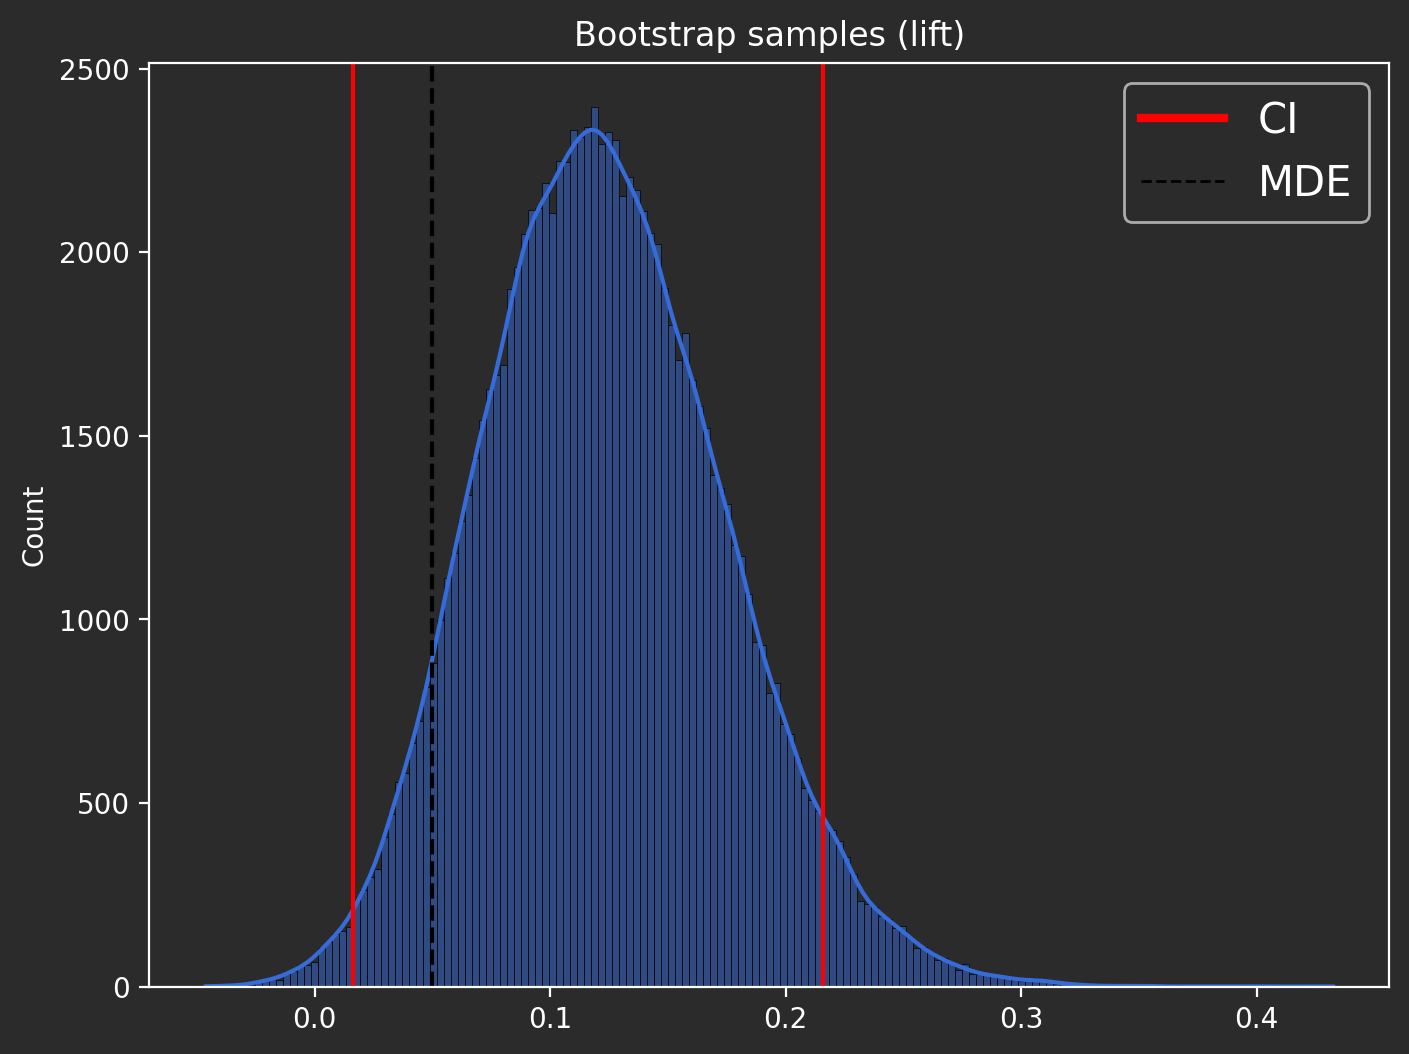

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.histplot(bootstrap.boot_metric_sample, kde=True, ax=ax)

ax.axvline(x=DESIGN_MDE, color='k', linestyle='--')
ax.axvline(x=bootstrap.ci_low, color='red', linestyle='-')
ax.axvline(x=bootstrap.ci_high, color='red', linestyle='-')
#ax.text((bootstrap.ci_high +bootstrap.ci_low) / 2, 2200, "CI", size=16, color="red")

legend_elements = [Line2D([0], [0], color="red", lw=3, label=f"CI"),
                   Line2D([0], [0], color="black", lw=1, label=f"MDE", linestyle="--")]

ax.legend(handles=legend_elements, loc="upper right", fontsize=15)
ax.set_title("Bootstrap samples (lift)")
plt.show()

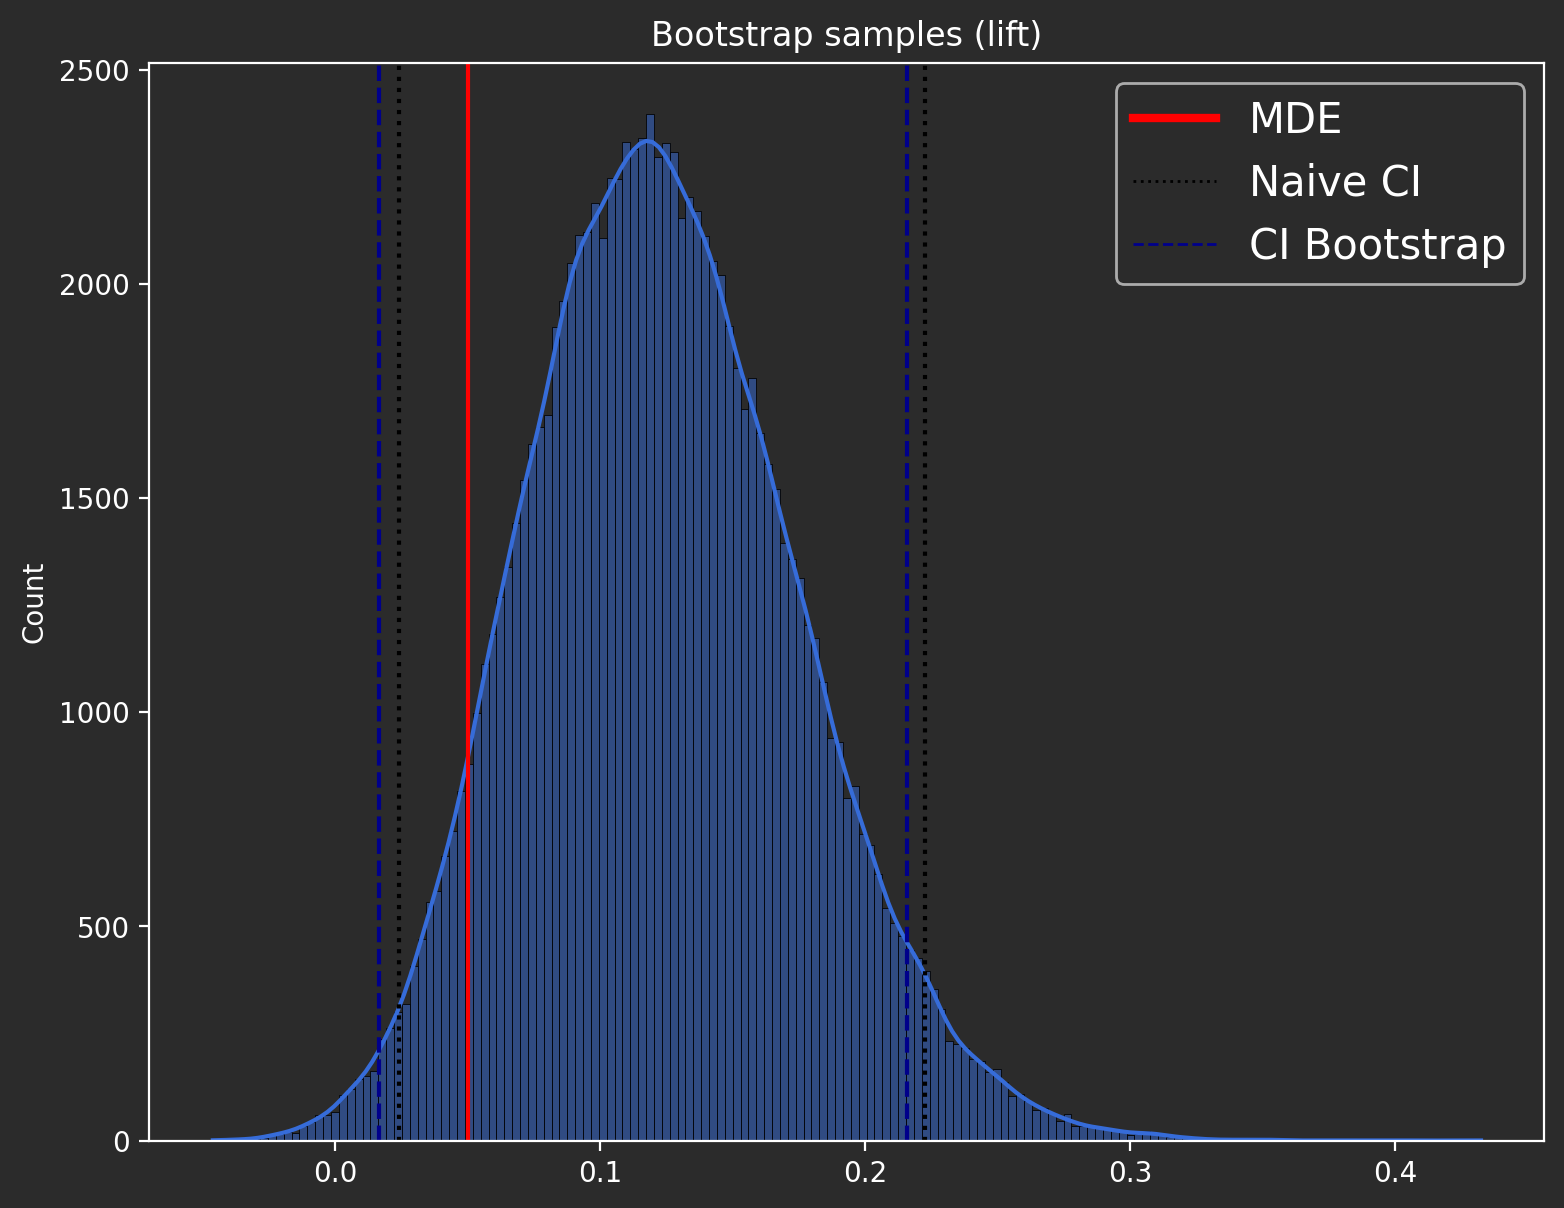

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.histplot(bootstrap.boot_metric_sample, kde=True, ax=ax)

ax.axvline(x=DESIGN_MDE, color='red', linestyle='-')
ax.axvline(x=naive[0], color="black", linestyle=':')
ax.axvline(x=naive[1], color="black", linestyle=':')
ax.axvline(x=bootstrap.ci_low, color="darkblue", linestyle='--')
ax.axvline(x=bootstrap.ci_high, color='darkblue', linestyle='--')
#ax.text((bootstrap.ci_high +bootstrap.ci_low_) / 2, 2200, "CI", size=16, color="red")

legend_elements = [Line2D([0], [0], color="red", lw=3, label=f"MDE"),
                   Line2D([0], [0], color="black", lw=1, label=f"Naive CI", linestyle=":"),
                   Line2D([0], [0], color="darkblue", lw=1, label=f"CI Bootstrap", linestyle="--")]

ax.legend(handles=legend_elements, loc="upper right", fontsize=15)
ax.set_title("Bootstrap samples (lift)")
plt.show()

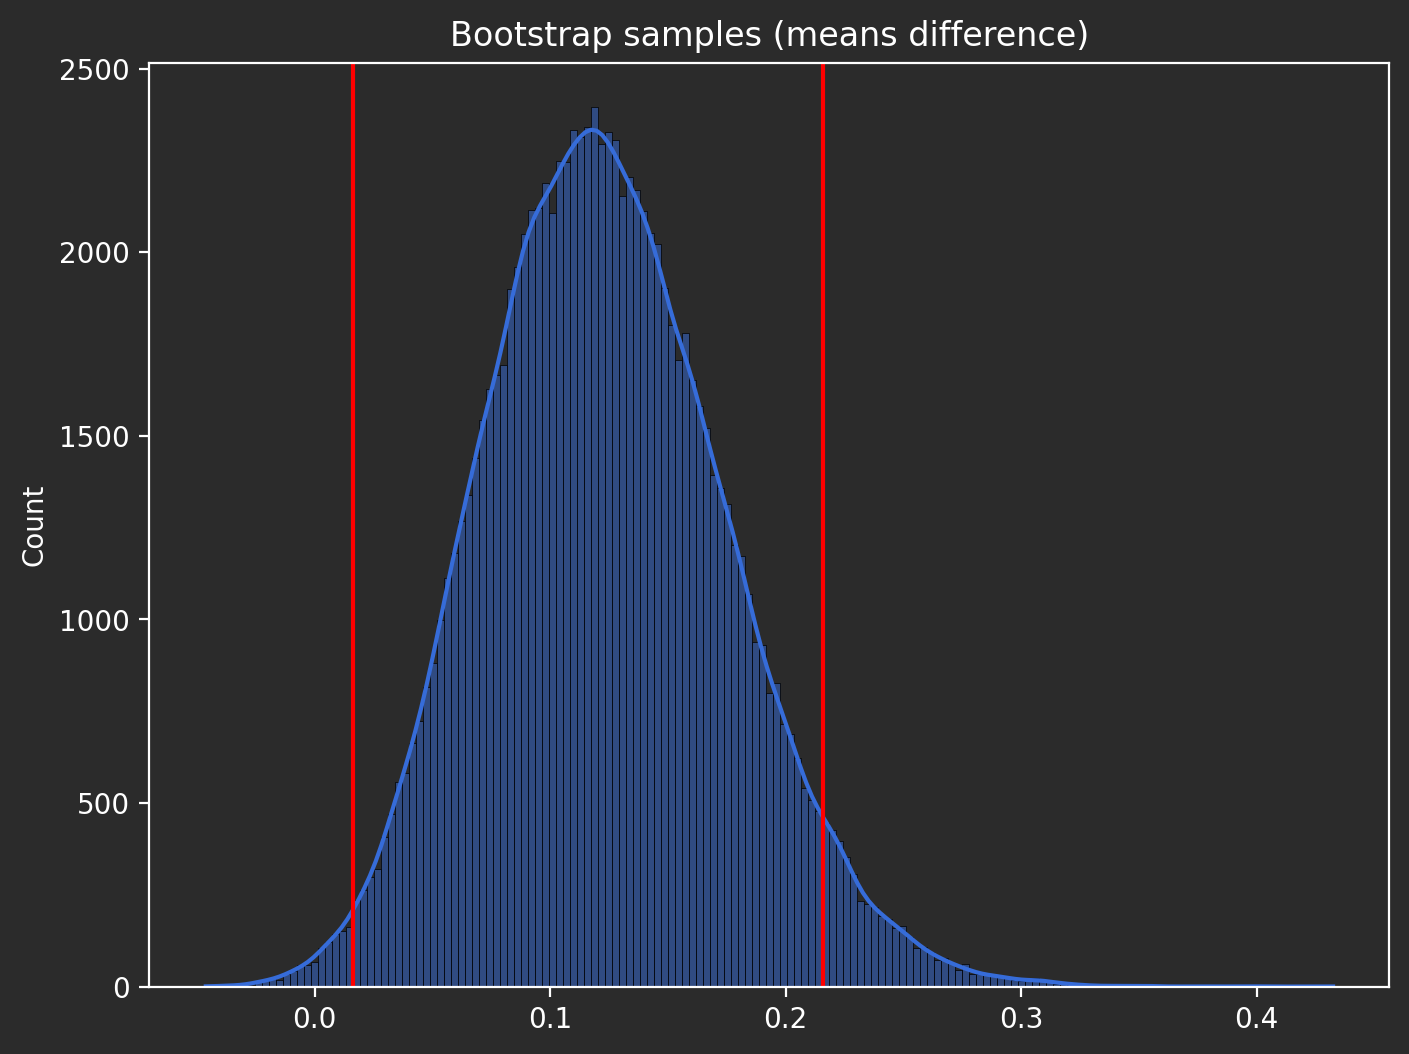

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.histplot(bootstrap.boot_metric_sample, kde=True, ax=ax)
ax.axvline(x=bootstrap.ci_low, color='red', linestyle='-')
ax.axvline(x=bootstrap.ci_high, color='red', linestyle='-')

ax.set_title("Bootstrap samples (means difference)")

#legend_elements = [Line2D([0], [0], color="red", lw=3, label=f"CI")]

#ax.legend(handles=legend_elements, loc="upper right", fontsize=15)
plt.show()

## A/A test
---
* Сплітування валідне

In [13]:
rng = np.random.default_rng(seed=42)
shuffled_arr = rng.permutation(control)
control_1, control_2 = np.array_split(shuffled_arr, 2)
a_a_test = MyBootstrap_2samp_perc(control_1, control_1, B=100_000).uplift_ci()

print("\t A/A test control")
print(f"CI: {a_a_test.ci_low:.4f} -- {a_a_test.ci_high:.4f}")
print("✅Good split!")

	 A/A test control
CI: -0.0551 -- 0.0525
✅Good split!


In [14]:
rng = np.random.default_rng(seed=42)
shuffled_arr = rng.permutation(test)
control_1, control_2 = np.array_split(shuffled_arr, 2)
a_a_test = (MyBootstrap_2samp_perc

            (control_1, control_1, B=100_000).uplift_ci())

print("\t A/A test test")
print(f"CI: {a_a_test.ci_low:.4f} -- {a_a_test.ci_high:.4f}")
print("✅Good split!")

	 A/A test test
CI: -0.1309 -- 0.1155
✅Good split!


## Poisson bootstrap
---
* Порівнюємо Poisson та звичайний та 10 000
* Порівнюємо `parallel=True` та `parallel=False`

In [15]:
%%timeit
poisson = MyBootstrap_2samp_perc(test, control, B=10_000).uplift_ci_pois(parallel=True)

print(f"CI: {poisson.ci_low:.4f} -- {poisson.ci_high:.4f}")

CI: 0.0145 -- 0.2168
CI: 0.0145 -- 0.2168
CI: 0.0145 -- 0.2168
CI: 0.0145 -- 0.2168
CI: 0.0145 -- 0.2168
CI: 0.0145 -- 0.2168
CI: 0.0145 -- 0.2168
CI: 0.0145 -- 0.2168
2.02 s ± 531 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [16]:
%%timeit
simple_bootstrap = MyBootstrap_2samp_perc(test, control, B=10_000).uplift_ci(parallel=True)

print(f"CI: {simple_bootstrap.ci_low:.4f} -- {simple_bootstrap.ci_high:.4f}")

CI: 0.0117 -- 0.2153
CI: 0.0117 -- 0.2153
CI: 0.0117 -- 0.2153
CI: 0.0117 -- 0.2153
CI: 0.0117 -- 0.2153
CI: 0.0117 -- 0.2153
CI: 0.0117 -- 0.2153
CI: 0.0117 -- 0.2153
The slowest run took 6.12 times longer than the fastest. This could mean that an intermediate result is being cached.
1.56 s ± 1.04 s per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [17]:
%%timeit
simple_bootstrap = MyBootstrap_2samp_perc(test, control, B=10_000).uplift_ci_pois(parallel=False)

print(f"CI: {simple_bootstrap.ci_low:.4f} -- {simple_bootstrap.ci_high:.4f}")

CI: 0.0145 -- 0.2156
CI: 0.0145 -- 0.2156
CI: 0.0145 -- 0.2156
CI: 0.0145 -- 0.2156
CI: 0.0145 -- 0.2156
CI: 0.0145 -- 0.2156
CI: 0.0145 -- 0.2156
CI: 0.0145 -- 0.2156
8.75 s ± 389 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [18]:
%%timeit
simple_bootstrap = MyBootstrap_2samp_perc(test, control, B=10_000).uplift_ci(parallel=False)

print(f"CI: {simple_bootstrap.ci_low:.4f} -- {simple_bootstrap.ci_high:.4f}")

CI: 0.0148 -- 0.2163
CI: 0.0148 -- 0.2163
CI: 0.0148 -- 0.2163
CI: 0.0148 -- 0.2163
CI: 0.0148 -- 0.2163
CI: 0.0148 -- 0.2163
CI: 0.0148 -- 0.2163
CI: 0.0148 -- 0.2163
1.51 s ± 86.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [19]:
from greenbowl_boot import load_country_stream

stream = load_country_stream(STUDENT_ID)
print(stream)                    # ~24 shards, ~1.2M users per arm in total
c0, t0 = stream.shard(0)         # one shard: ~50k per arm

<CountryStream n_shards=22 n_control=1,118,232 n_test=1,085,962 (one shard at a time!)>


In [20]:
print(f"Breakeven: {BREAKEVEN}")
for i in reversed(range(stream.n_shards)):
    bootstrap_shard = MyBootstrap_2samp_perc(stream.shard(i)[1], stream.shard(i)[0], B=10_000).uplift_ci(parallel=True)
    print(f"Shard: {i} \t CI: {bootstrap_shard.ci_low:.4f} -- {bootstrap_shard.ci_high:.4f} \t ✅ Effect higher Breakeven (BREAKEVEN > CI low)"
          if bootstrap_shard.ci_low> BREAKEVEN else
          f"Shard: {i} \t CI: {bootstrap_shard.ci_low:.4f} -- {bootstrap_shard.ci_high:.4f} \t ⛔ Effect less Breakeven (BREAKEVEN < CI low)")

Breakeven: 0.03
Shard: 21 	 CI: 0.0289 -- 0.0538 	 ⛔ Effect less Breakeven (BREAKEVEN < CI low)
Shard: 20 	 CI: 0.0258 -- 0.0509 	 ⛔ Effect less Breakeven (BREAKEVEN < CI low)
Shard: 19 	 CI: 0.0458 -- 0.0707 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shard: 18 	 CI: 0.0440 -- 0.0692 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shard: 17 	 CI: 0.0410 -- 0.0671 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shard: 16 	 CI: 0.0341 -- 0.0586 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shard: 15 	 CI: 0.0410 -- 0.0658 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shard: 14 	 CI: 0.0381 -- 0.0626 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shard: 13 	 CI: 0.0375 -- 0.0627 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shard: 12 	 CI: 0.0365 -- 0.0624 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shard: 11 	 CI: 0.0354 -- 0.0602 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shard: 10 	 CI: 0.0342 -- 0.0597 	 ✅ Effect higher Breakeven (BREAKEVEN > CI low)
Shar

In [21]:
"""
for i in reversed(range(stream.n_shards)):
    bootstrap_shard = MyBootstrap_2samp(stream.shard(i)[1], stream.shard(i)[0], B=10_000).uplift_ci(parallel=False)
    print(f"Shard: {i} \t CI: {bootstrap_shard.ci_low:.4f} -- {bootstrap_shard.ci_high:.4f}")
"""
"""
for i in reversed(range(stream.n_shards)):
    bootstrap_shard = MyBootstrap_2samp(stream.shard(i)[1], stream.shard(i)[0], B=10_000).uplift_ci_pois(parallel=True)
    print(f"Shard: {i} \t CI: {bootstrap_shard.ci_low:.4f} -- {bootstrap_shard.ci_high:.4f} \t ✅ Effect higher Breakeven (BREAKEVEN > CI low)"
      if bootstrap_shard.ci_low_perc > BREAKEVEN else
      f"Shard: {i} \t CI: {bootstrap_shard.ci_low:.4f} -- {bootstrap_shard.ci_high:.4f} \t ⛔ Effect less Breakeven (BREAKEVEN < CI low)")
"""
"""
 for i in reversed(range(stream.n_shards)):
    bootstrap_shard = MyBootstrap_2samp(stream.shard(i)[1], stream.shard(i)[0], B=10_000).uplift_ci_pois(parallel=False)
    print(f"Shard: {i} \t CI: {bootstrap_shard.ci_low:.4f} -- {bootstrap_shard.ci_high:.4f}")
"""

print("Працює повільніше")

Працює повільніше


In [22]:
control_zero = control[control == 0]
control_withot_0 = control[control != 0]
def city_world(n, rng, uplift=0.0):
    target_mean = np.mean(control_withot_0)
    target_var = np.var(control_withot_0, ddof=1)

    var_ratio = target_var / (target_mean ** 2)
    mu = np.log(target_mean ** 2 / np.sqrt(target_var + target_mean ** 2))
    sigma = np.sqrt(np.log(var_ratio + 1))

    return rng.lognormal(mean=mu+uplift, sigma=sigma, size=n)

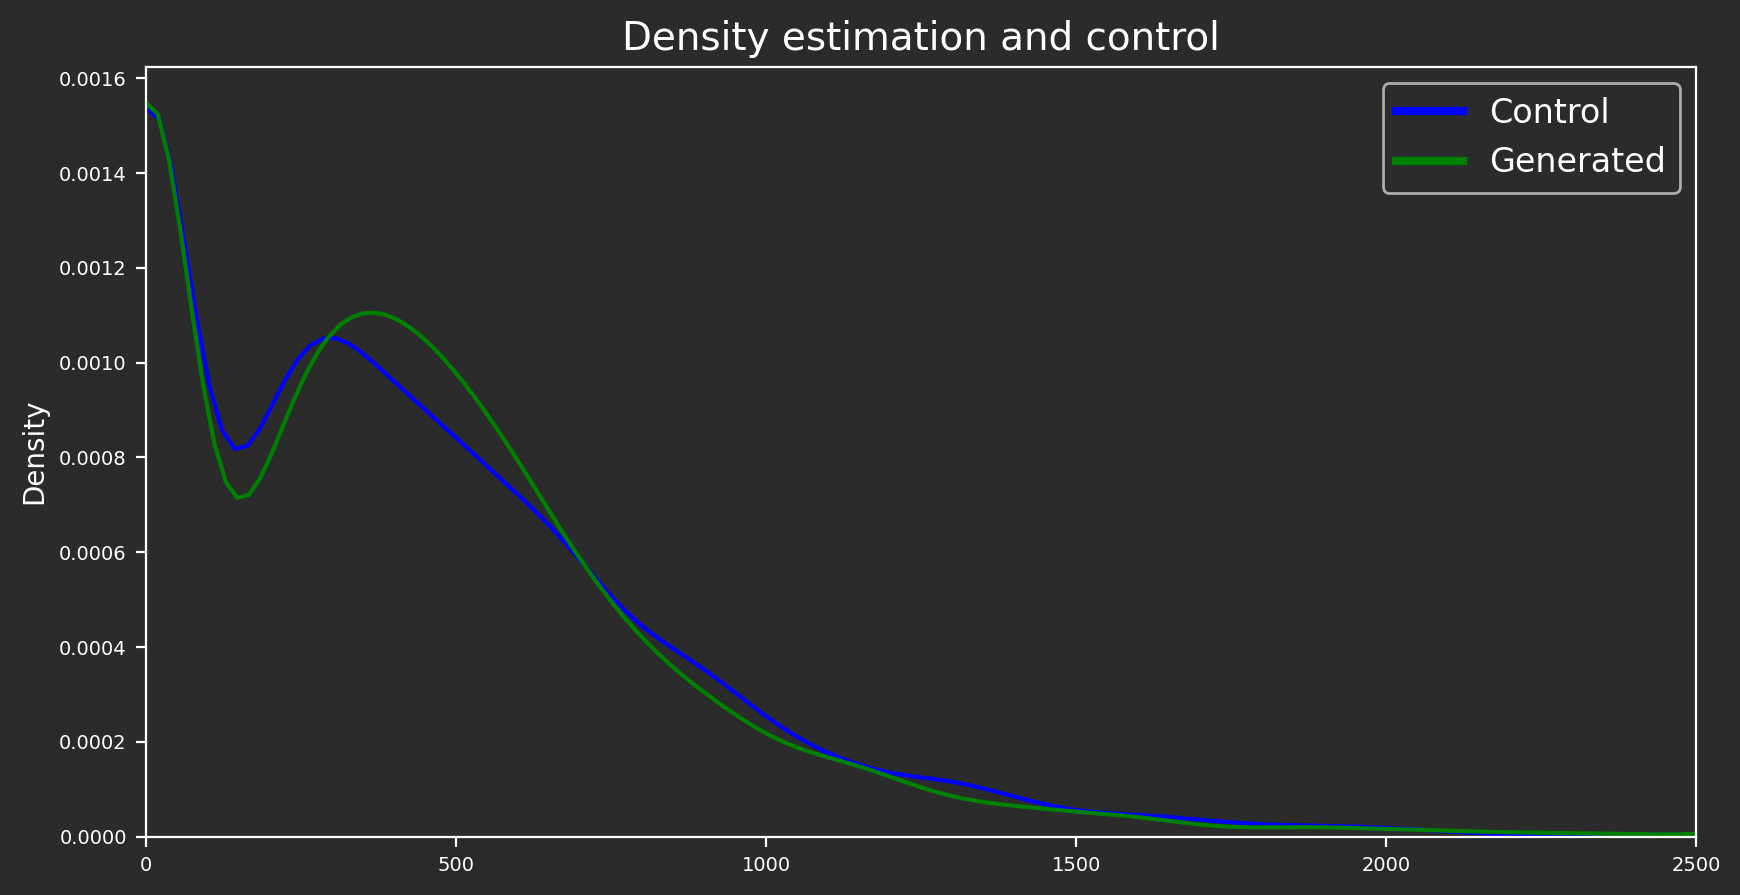

In [23]:
rng = np.random.default_rng(42)
city_world_sample = city_world(len(control_withot_0), rng)

city_world_sample = np.append(city_world_sample, control_zero)
fig, ax = plt.subplots(figsize=(10, 5))

sns.kdeplot(control, ax=ax, color="blue")
sns.kdeplot(city_world_sample, color="green", ax=ax)

ax.set_xlim(0, 2500)

legend_elements = [Line2D([0], [0], color="blue", lw=3, label=f"Control"),
                   Line2D([0], [0], color="green", lw=3, label=f"Generated"),]

ax.legend(handles=legend_elements, loc="upper right", fontsize=12)
ax.tick_params(axis="both", which="major", labelsize=7)
ax.set_title("Density estimation and control", fontsize=14)

plt.show()

In [24]:
@dataclass(slots=True)
class Rate:
    rate: float
    ci_low: float
    ci_high: float

def rate_uplift(n1, n2, rng, B=1000, exps=1000, alpha=0.05, uplift=0):
    rejects = 0
    for _ in range(exps):
        test = city_world(n1, rng, uplift=uplift)
        control = city_world(n2, rng)
        bootstrap = MyBootstrap_2samp_perc(test, control, B=B, alpha=alpha).uplift_ci(parallel=True)
        rejects +=1 if  bootstrap.ci_low > 0 or bootstrap.ci_high < 0 else 0
    ci_low, ci_high = proportion_confint(rejects, exps, alpha=alpha)
    return Rate(rejects/exps, ci_low, ci_high)

In [25]:
def worker(n1, n2, seed, B=10_000, alpha=0.05, uplift=0.0):
    rng = np.random.default_rng(seed)

    test = city_world(n1, rng, uplift=uplift)
    control = city_world(n2, rng)
    bootstrap = MyBootstrap_2samp_perc(test, control, B=B, alpha=alpha).uplift_ci(parallel=False)
    return 1 if  bootstrap.ci_low_perc > 0 or bootstrap.ci_high < 0 else 0

def rate_uplift_v2(n1, n2, seed, B=10_000, exps=1_000, alpha=0.05, uplift=0.0):
    basic_seed = np.random.SeedSequence(seed)
    seeds = basic_seed.spawn(B)

    rejects = Parallel(n_jobs=-1, prefer="threads")(delayed(worker)(n1, n2, seed, B=B, alpha=alpha, uplift=uplift) for seed in seeds)
    ci_low, ci_high = proportion_confint(sum(rejects), exps, alpha=alpha)
    return Rate(sum(rejects)/exps, ci_low, ci_high)

In [26]:
rng = np.random.default_rng(42)
result = rate_uplift(len(control), len(test), rng)

In [27]:
# Працює довго
#result_v2 = rate_uplift_v2(len(control), len(test), 42)

In [28]:
print("\t Valid test")
print(f"FPR: {result.rate:.4f}")
print(f"CI: {result.ci_low:.4f} -- {result.ci_high:.4f}")

	 Valid test
FPR: 0.0540
CI: 0.0400 -- 0.0680


In [29]:
result = rate_uplift(len(control), len(test), rng, uplift = DESIGN_MDE)
print("\t Power")
print(f"Power: {result.rate:.4f} \t Uplift: {DESIGN_MDE:.4f} \t CI: {result.ci_low:.4f} -- {result.ci_high:.4f}")

	 Power
Power: 0.9600 	 Uplift: 0.0500 	 CI: 0.9479 -- 0.9721


# Make Report
---

In [30]:
@dataclass(slots=True)
class Report:
    ci_low: float
    ci_high: float
    p_profitable: float
    uplift: float
    decision: str
    ev: float

def ab_report(control, test, breakeven, annual_revenue, alpha=0.05, stat: function=np.mean, is_trim=False, trim=0.005):
    if is_trim:

        lower_bound_coontrol = np.quantile(control, trim)
        high_bound_coontrol = np.quantile(control, 1 - trim)
        control = control[(control >= lower_bound_coontrol) & (control <= high_bound_coontrol)]

        lower_bound_test = np.quantile(test, trim)
        high_bound_test = np.quantile(test, 1 - trim)
        test = test[(test >= lower_bound_test) & (test <= high_bound_test)]

    uplift = stat(test) / stat(control) - 1

    bootstrap = MyBootstrap_2samp_perc(test, control, B=10_000, alpha=alpha, stat=stat).uplift_ci()

    ev = annual_revenue * (uplift - breakeven)

    z_critical = norm.ppf((2 - alpha) / 2)
    se = (bootstrap.ci_high - bootstrap.ci_low) / 2 * z_critical
    p_profitable = norm.sf(breakeven, uplift, se)

    decision = "Shipe" if uplift > bootstrap.ci_high else("Grey" if bootstrap.ci_low < uplift else "Kill")
    return Report(bootstrap.ci_low, bootstrap.ci_high, p_profitable , uplift, decision, ev)


## Report with mean (lift)

In [31]:
report = ab_report(control, test, BREAKEVEN, exp.annual_revenue)

print(f"\t Report")
print(f"Uplift: {report.uplift:.4f}")
print(f"CI: {report.ci_low:.4f} -- {report.ci_high:.4f}")
print(f"P(Profitable): {report.p_profitable:.4f}")
print(f"Decision: {report.decision}")
print(f"EV: {report.ev:.4f}")

	 Report
Uplift: 0.1233
CI: 0.0117 -- 0.2153
P(Profitable): 0.6798
Decision: Grey
EV: 99291297.2050


## Report with median (lift)

In [32]:
report = ab_report(control, test, BREAKEVEN, exp.annual_revenue, stat=np.median)

print(f"\t Report")
print(f"Uplift: {report.uplift:.4f}")
print(f"CI: {report.ci_low:.4f} -- {report.ci_high:.4f}")
print(f"P(Profitable): {report.p_profitable:.4f}")
print(f"Decision: {report.decision}")

	 Report
Uplift: -0.0052
CI: -0.0593 -- 0.0506
P(Profitable): 0.3721
Decision: Grey


## Report with trim sample (lift)

In [33]:
## Report with median (lift)
report = ab_report(control, test, BREAKEVEN, exp.annual_revenue, is_trim=True, trim=0.005)

print(f"\t Report")
print(f"Trim: 0.5%")
print(f"Uplift: {report.uplift:.4f}")
print(f"CI: {report.ci_low:.4f} -- {report.ci_high:.4f}")
print(f"P(Profitable): {report.p_profitable:.4f}")
print(f"Decision: {report.decision}")

	 Report
Trim: 0.5%
Uplift: -0.0038
CI: -0.0416 -- 0.0328
P(Profitable): 0.3214
Decision: Grey


## Power by simulation
---

In [34]:
result = rate_uplift(len(control), len(test), rng)
print("\t Power")
print(f"Power: {result.rate:.4f} \t Uplift: {DESIGN_MDE:.4f} \t CI: {result.ci_low:.4f} -- {result.ci_high:.4f}")

	 Power
Power: 0.0530 	 Uplift: 0.0500 	 CI: 0.0391 -- 0.0669


## Memo
---
* На перший погляд жл достатньо підстав відхилити $H_0$ про це нам каже `t-тест` і `bootstrap`
* Але якщо прибрати екстимальні значення, то ефекту нема. Тобто коли ми порівнюємо медіани або беремо усічене середнє
* Звичайний `bootstrap` що працює в паралельно показва найбільшу швидкість
* Power: 0.9610
* FPR: 0.05 in CI (Wilson)